# ДЗ1. Top-10 рекомендации товаров категории Video Games

**Шевела Артём**

Сравниваются ItemKNN, iALS, EASE, FM и ALS с временным целевым сигналом.
Задача - рекомендовать десять товаров, ещё не встречавшихся пользователю.
Наблюдение в данных - отзыв с оценкой 1–5, а не подтверждённая покупка или время игры.
Релевантным считается будущий отзыв с оценкой не ниже 4.

Основная метрика выбора параметров - NDCG@10; дополнительно оценивается Recall@10.

## Запуск

Python 3.12. Из корня репозитория:

```bash
cd hw1
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
.venv/bin/python execute_notebook.py
```

Либо можно открыть ноутбук с ядром этого окружения и выполнить Run All.
Архивы автоматически загружаются в `data/raw/`; данные и окружение исключены из Git.
При повторном запуске проверяются SHA-256 исходных файлов.
Параметры разбиения и поиска находятся в `config.py`, результаты - в `results/`.
Зерно случайности - 42, число потоков BLAS - 1.

In [1]:
import os, sys, json, random
from pathlib import Path
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from IPython.display import display
from threadpoolctl import threadpool_limits
import config
from data_utils import prepare_data
from run_experiments import run_all
random.seed(config.SEED)
np.random.seed(config.SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0], '| seed:', config.SEED, '| primary metric:', config.PRIMARY_METRIC)

Python: 3.12.3 | seed: 42 | primary metric: NDCG@10


## 1. Данные

Используется **Amazon Reviews 2023, Video_Games, официальный 5-core**.
[Описание и поля](https://amazon-reviews-2023.github.io/main.html),
[вариант 5-core](https://amazon-reviews-2023.github.io/data_processing/5core.html).

- [Взаимодействия, CSV.gz](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Video_Games.csv.gz).
- [Метаданные товаров, JSONL.gz](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Video_Games.jsonl.gz).

`user_id` - анонимный пользователь, `parent_asin` - товар с объединёнными вариантами,
`rating` - оценка, `timestamp` - время отзыва в миллисекундах Unix.
По `parent_asin` присоединяются название, категории, магазин, бренд и наличие описания.
В категории есть и игры, и аксессуары.

Официальный 5-core выделен по всему периоду. Поэтому исходная популяция уже выбрана
ретроспективно по активности, и эксперимент не описывает всех посетителей Amazon.
Дополнительные каталог и когорта ниже отбираются только по train.

In [2]:
data = prepare_data()
summary = data['summary']
display(pd.DataFrame([
    {'stage': 'Source 5-core', 'interactions': summary['source_rows'], 'users': summary['source_users'], 'items': summary['source_items']},
    {'stage': 'Selected clean sample', 'interactions': summary['selected_rows'], 'users': summary['users'], 'items': summary['items']},
]))
print('Source SHA-256:', json.dumps(summary['sha256'], indent=2))
assert 100_000 <= summary['selected_rows'] <= 2_000_000
assert summary['users'] >= 1000 and summary['items'] >= 1000

,stage,interactions,users,items
0,Source 5-core,814586,94762,25612
1,Selected clean sample,256100,30000,4000


Source SHA-256: {
  "Video_Games.csv.gz": "a2bde5f3b945960d161538c200dd87845e6ee471b46da96410dde61613c6901c",
  "meta_Video_Games.jsonl.gz": "ced9696b0874121327a438bfe9d3d01aba45da158e58f94f4920352d75fc1fc9"
}


## 2. EDA и подготовка

Удаляем пропуски в обязательных полях и некорректные оценки/времена.
Если одна пара встречается повторно, сохраняем самый ранний отзыв: задача про открытие нового товара,
а не предсказание повторной покупки. Сортировка и разрешение равенств детерминированы.

Чтобы ограничить затраты памяти при обучении EASE, каталог ограничен 4 000 самыми частыми товарами **по train**,
при равенстве - по `parent_asin`. Требуем от пользователя ≥5 train-наблюдений в этом каталоге.
До 30 000 пользователей выбираем по SHA-256 строки `seed:cohort:user_id`, а затем сортируем ID.
Объекты, не встретившиеся в train выбранных пользователей, исключаем. Все последующие отзывы
этих пользователей в фиксированном каталоге сохраняем, включая низкие оценки.
Выборка смещена к популярным товарам и активным пользователям; это осознанное ограничение.

missing_required            0.000000
exact_duplicates            0.000000
repeated_user_item_pairs    0.000000
sparsity                    0.997866
dtype: float64

,field,items_present,coverage
0,title,3999,0.99975
1,categories,3931,0.98275
2,brand,538,0.13450
3,store,3994,0.99850
4,description_present,3644,0.91100


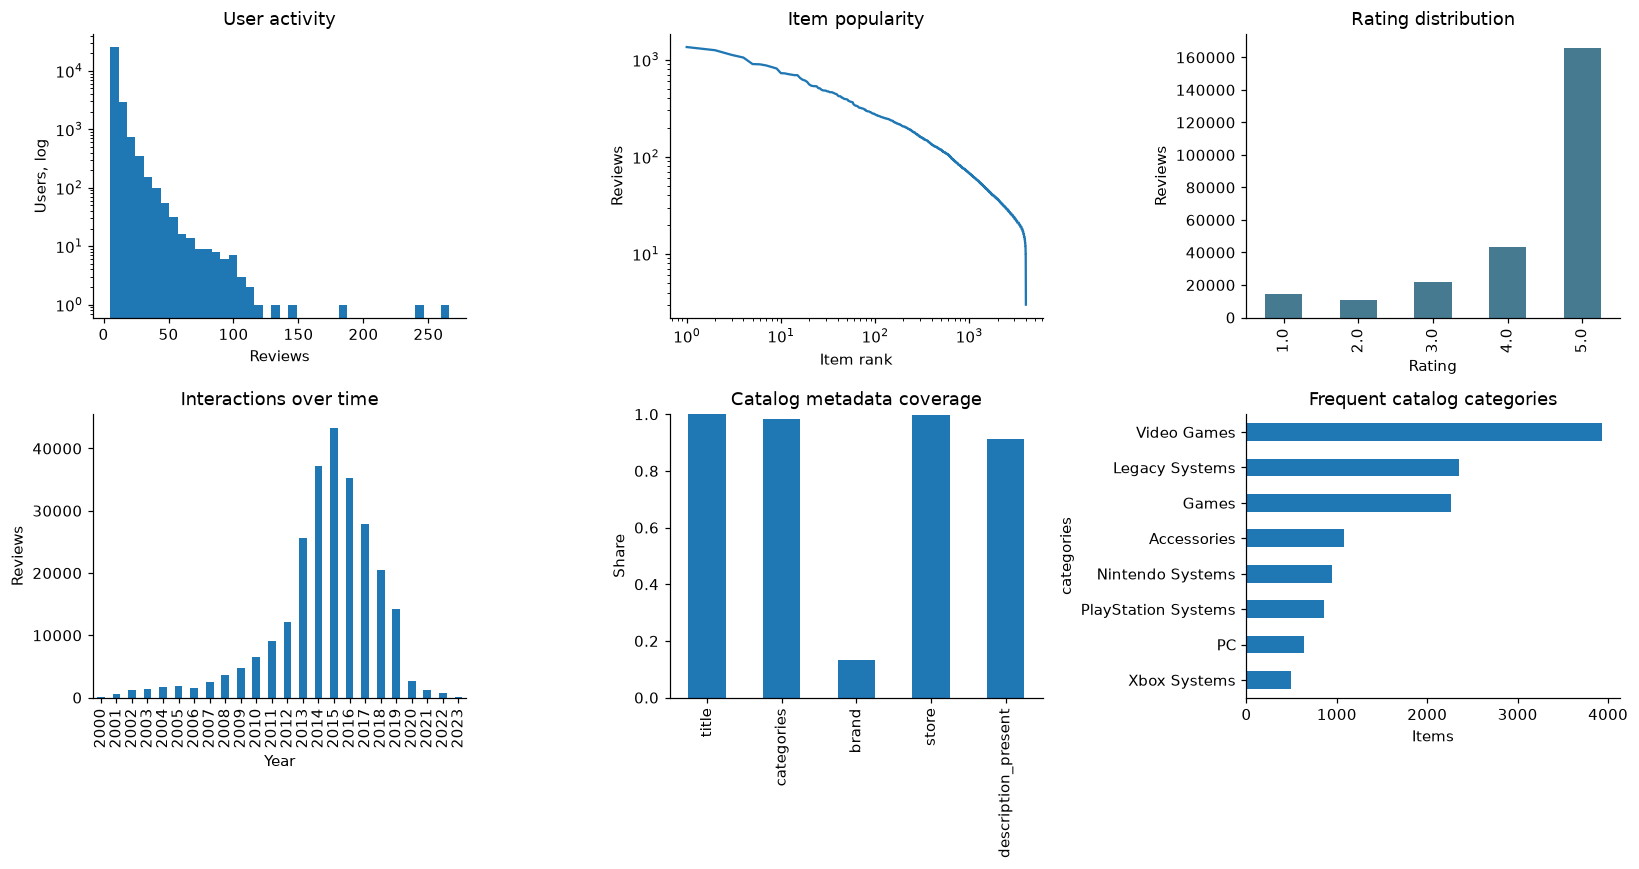

,parent_asin,title,categories,brand
0,0375869026,Wonder,"[Video Games, PC, Games]",
1,9629971372,Dotop Sony Playstation 2 PS2 64MB Memory Card,"[Video Games, Legacy Systems, PlayStation Systems, PlayStation 2, Accessories]",
2,9861019731,Memory Card for Wii Console 64 MB (1019 Blocks),"[Video Games, Legacy Systems, Nintendo Systems, Wii, Accessories, Memory]",
3,9882155456,"2 Pack - Gator Crunch Wii Gamecube 6FT Extension Cable / Cord (Lifetime Warranty, Bulk packaging)","[Video Games, Legacy Systems, Nintendo Systems, Wii]",
4,B00000DMAQ,Banjo-Kazooie - Nintendo 64,"[Video Games, Legacy Systems, Nintendo Systems, Nintendo 64, Games]",


In [3]:
events = data['interactions']
user_activity = events.groupby('user_idx').size()
item_activity = events.groupby('item_idx').size().sort_values(ascending=False)
display(pd.Series({'missing_required': sum(summary['missing'].values()), 'exact_duplicates': summary['exact_duplicates'],
                  'repeated_user_item_pairs': summary['repeated_pairs'], 'sparsity': summary['sparsity']}))
display(pd.DataFrame({'field': summary['metadata_coverage'].keys(), 'items_present': summary['metadata_coverage'].values()})
        .assign(coverage=lambda x: x.items_present / data['n_items']))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0,0].hist(user_activity, bins=40, log=True); axes[0,0].set(title='User activity', xlabel='Reviews', ylabel='Users, log')
axes[0,1].plot(np.arange(1,len(item_activity)+1), item_activity.to_numpy()); axes[0,1].set(xscale='log', yscale='log', title='Item popularity', xlabel='Item rank', ylabel='Reviews')
events.rating.value_counts().sort_index().plot.bar(ax=axes[0,2], color='#467a91'); axes[0,2].set(title='Rating distribution', xlabel='Rating', ylabel='Reviews')
pd.to_datetime(events.timestamp, unit='ms', utc=True).dt.year.value_counts().sort_index().plot.bar(ax=axes[1,0]); axes[1,0].set(title='Interactions over time', xlabel='Year', ylabel='Reviews')
pd.Series(summary['metadata_coverage']).div(data['n_items']).plot.bar(ax=axes[1,1]); axes[1,1].set(title='Catalog metadata coverage', ylim=(0,1), ylabel='Share')
categories = data['metadata'].categories.dropna().explode().dropna().astype(str).value_counts().head(8)
categories.sort_values().plot.barh(ax=axes[1,2]); axes[1,2].set(title='Frequent catalog categories', xlabel='Items')
plt.tight_layout(); plt.show()
display(data['metadata'][['parent_asin','title','categories','brand']].head(5))

В обязательных полях нет пропусков, точных дубликатов и повторных пар user–item.
Матрица разрежена на **99,7866%**; распределения активности и популярности имеют длинный хвост.
Поэтому для хранения взаимодействий используются разреженные матрицы, а каталог для EASE ограничен.

Названия есть у **3 999 из 4 000** товаров, категории - у **3 931**, бренды - только у **538**.
Требование полного бренда отбросило бы значительную часть каталога. Метаданные не используются
как основание для удаления товара; отсутствие истории их изменения отдельно ограничивает их
использование при обучении.

## 3. Единый протокол оценки

Глобальные границы - 80% и 90% квантиль timestamp очищенного исходного файла,
до ограничения каталога/когорты. `train: t<T₁`, `validation: T₁≤t<T₂`, `test: t≥T₂`.
Одинаковые timestamp не разрезаются. Это единая историческая граница для всех пользователей;
leave-last-out по пользователям не используется.

На validation обучаем по train и строим рекомендации в T₁. После выбора всех настроек
переобучаем по train+validation и строим рекомендации в T₂. Test до этого не оцениваем.
Каталог остаётся фиксированным, сформированным по исходному train, и не расширяется.

Новые пользователи/товары вне когорты не оцениваются: это warm-start постановка.
В каждом holdout берём пользователей хотя бы с одним релевантным событием в каталоге;
если их больше 1 500 - фиксированная SHA-256 выборка с seed 42.
Во всех пяти моделях используются одни и те же массивы пользователей соответствующего holdout.
Оценка относится только к выбранной когорте и каталогу.

Кандидаты - **весь фиксированный каталог**, кроме любых ранее известных объектов пользователя,
включая низко оценённые. Sampling кандидатов при оценке отсутствует.
Пары user-item уникальны, поэтому ground truth не пересекается с ранее известными.
При равных score предпочтение меньшему закодированному item ID (исходные ID отсортированы).
Для каждого пользователя формируются 10 различных рекомендаций из доступных ему кандидатов.

Для бинарной релевантности $rel_{u,j}=I[r_{u,j}\ge4]$:

$$Recall@10(u)=\frac{|R_u\cap Top10_u|}{|R_u|},\qquad
NDCG@10(u)=\frac{\sum_{j=1}^{10}rel_{u,j}/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Обе усредняем по пользователям. Recall измеряет долю найденных релевантных объектов,
NDCG дополнительно учитывает порядок: хорошие товары выше в десятке полезнее пользователю.
Нет наблюдений о показах/экспозиции, поэтому метрики не являются оценкой онлайн-эффекта.

Важно: 80/10/10 относится к исходному файлу до отбора. После ограничения каталога и пользователей
получается 250 926 / 3 883 / 1 291 событий, то есть 97,98% выбранных событий находятся в train.
В test остаётся 1,58% событий исходного test-периода. Это существенное ограничение покрытия,
а не полноценная оценка всего исходного каталога.

In [4]:
display(pd.Series({key: summary[key] for key in ['train_rows','validation_rows','test_rows','train_cutoff_utc',
    'validation_cutoff_utc','excluded_validation_rows','excluded_test_rows','validation_users_evaluated','test_users_evaluated']}))
assert set(data['validation'].user_idx) <= set(data['train'].user_idx)
assert set(data['test'].item_idx) <= set(data['train'].item_idx)
print('Catalog size:', data['n_items'], '| same catalog for every model, no sampled evaluation negatives')

train_rows                                              250926
validation_rows                                           3883
test_rows                                                 1291
train_cutoff_utc              2019-12-10 03:24:35.894000+00:00
validation_cutoff_utc         2021-07-09 19:25:00.426000+00:00
excluded_validation_rows                                 77575
excluded_test_rows                                       80169
validation_users_evaluated                                1500
test_users_evaluated                                       677
dtype: object

Catalog size: 4000 | same catalog for every model, no sampled evaluation negatives


## 4. Модели

Реализации моделей находятся в `models/`, формирование рекомендаций и метрики - в `evaluation.py`.
Обозначим $X_{ui}=I[r_{ui}\ge4]$, отсутствие положительного отзыва даёт ноль.

**ItemKNN** (`models/item_knn.py`). Косинус по положительным историям:
$s_{ij}=\frac{n_{ij}}{\sqrt{n_i n_j}}\frac{n_{ij}}{n_{ij}+\gamma}$, $s_{ii}=0$.
Оставляем k самых близких исходящих соседей товара, прогноз $\hat s_u=X_uS$.
Множитель с $\gamma$ подавляет сходства с малой совместной поддержкой.

**iALS** (`models/ials.py`, общий solver в `_als.py`). Минимизируем
$\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda(\|x\|_F^2+\|y\|_F^2)$,
где $p_{ui}=I[r_{ui}\ge4]$, $c_{ui}=1+\alpha I[(u,i)\ observed]$.
Низкие/нейтральные оценки - наблюдённые нули с повышенным confidence.
Поочерёдно решаем нормальные уравнения по пользователям и товарам, например
$(Y^TY+\alpha Y_{obs}^TY_{obs}+\lambda I)x_u=(1+\alpha)Y_{obs}^Tp_{obs}$.
Рекомендации ранжируются по скалярным произведениям.

**EASE** (`models/ease.py`). Решаем
$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2$, $diag(B)=0$.
Для $P=(X^TX+\lambda I)^{-1}$ получаем $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$.
Обращение реализовано решением систем с разложением Холецкого. Прогноз - $X_uB$.

**FM второго порядка** (`models/fm.py`). Для вектора признаков $z$:
$\hat s(z)=w_0+\sum_jw_jz_j+\frac12\sum_f[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2]$.
Обучение - mini-batch AdaGrad по логистической функции потерь. Для примера $l$
с активными признаками $F_l$ штрафуются только соответствующие параметры:
$$L=\frac{1}{N}\sum_l\left[\log(1+e^{s_l})-y_ls_l+
\frac{\lambda}{2}\sum_{j\in F_l}(w_j^2+\|v_j\|^2)\right].$$
Это регуляризация с учётом частоты появления признака, а не полный L2 всех параметров на каждом шаге.
Метка положительного события - оценка ≥4; есть наблюдённые низкие оценки
и воспроизводимые негативные примеры из уже существовавшего на момент события каталога.
Ненаблюдённые негативы - обучающее предположение, а не истинная неприязнь.

Помимо user/item ID, FM использует **временные метаданные взаимодействий и исторические атрибуты**:
прошлую активность/оценки пользователя и товара, календарный контекст и возраст истории.
Используются 13 полей с one-hot кодированием: user/item ID; для каждого из пользователя и товара - число прошлых событий, средняя оценка, доля оценок ≥4, дни с последнего события и длительность истории; отдельно месяц запроса. Числа кодируются фиксированными интервалами, неизвестная история имеет отдельное значение; границы указаны в `models/fm.py`. На каждой обучающей строке все агрегаты
построены строго до её timestamp; одинаковые timestamp обрабатываются вместе, затем обновляют историю.
При предсказании доступны лишь обучающая история и общий момент T₁/T₂, а не время будущего отзыва.
Это метапризнаки пользователей/товаров/взаимодействий сверх ID: активность отражает надёжность
истории, прошлые оценки - предпочтения, время - смену интереса и давность товара.

Снимок названий/категорий/брендов не имеет истории изменения и не подтверждает доступность в прошлом.
Поэтому эти внешние поля используются для EDA и читаемого показа рекомендаций;
`average_rating`, `rating_number`, текущая цена, `bought_together`, helpful votes и текст будущего отзыва
в FM не входят. Здесь проверяется эффект **дополнительных временных и исторических признаков**,
а не эффект контентных категорий/брендов. Абляция - та же FM только с ID.

**ALS с кастомным целевым сигналом** (`models/custom_als.py`):

$$p^{custom}_{ui}=\frac{r_{ui}-3}{2}\,2^{-\frac{T_{cut}-t_{ui}}{86400000\,H}}\quad\text{для наблюдений},
\qquad p^{custom}_{ui}=0\quad\text{для отсутствующих пар}.$$

$H=365$ суток выбран заранее. Оценки 1–2 отрицательны, 3 нейтральна, 4–5 положительны;
старые предпочтения ослабевают. Гипотеза: свежая выраженная удовлетворённость лучше предсказывает
будущую рекомендацию. Это меняет **таргет**, а не только confidence. Solver, confidence и сетка ALS
одинаковы с базовым iALS; в контролируемой проверке совпадают все настройки, кроме таргета.
Критерий релевантности на validation/test по-прежнему оценка ≥4, без временного ослабления.

Теоретические источники: [weighted ALS, Hu et al.](https://yifanhu.net/PUB/cf.pdf),
[EASE, Steck](https://arxiv.org/abs/1905.03375),
[FM, Rendle](https://www.ismll.uni-hildesheim.de/pub/pdfs/Rendle2010FM.pdf).

In [5]:
from models.fm import FactorizationMachine
search_table = pd.DataFrame([{'model': name, 'trial': j+1, 'parameters': json.dumps(params, sort_keys=True)}
    for name, space in config.SEARCH_SPACES.items() for j,params in enumerate(space)])
display(search_table)
print('Primary metric fixed before tuning:', config.PRIMARY_METRIC)
print('Three validation configurations per family. Ties: first declared configuration.')

,model,trial,parameters
0,ItemKNN,1,"{""neighbors"": 30, ""shrinkage"": 10.0}"
1,ItemKNN,2,"{""neighbors"": 80, ""shrinkage"": 10.0}"
2,ItemKNN,3,"{""neighbors"": 80, ""shrinkage"": 50.0}"
3,iALS,1,"{""alpha"": 10.0, ""factors"": 16, ""iterations"": 8, ""regularization"": 1.0}"
4,iALS,2,"{""alpha"": 10.0, ""factors"": 24, ""iterations"": 8, ""regularization"": 5.0}"
5,iALS,3,"{""alpha"": 30.0, ""factors"": 24, ""iterations"": 8, ""regularization"": 5.0}"
6,EASE,1,"{""regularization"": 50.0}"
7,EASE,2,"{""regularization"": 200.0}"
8,EASE,3,"{""regularization"": 800.0}"
9,FM,1,"{""epochs"": 6, ""factors"": 8, ""learning_rate"": 0.03, ""regularization"": 0.0001}"


Primary metric fixed before tuning: NDCG@10
Three validation configurations per family. Ties: first declared configuration.


## 5. Подбор параметров и test

Для каждой из пяти моделей проверяются три конфигурации из таблицы выше.
Выбор - по NDCG@10 на validation; при равенстве остаётся первая конфигурация.
Бюджет одинаков по числу конфигураций, но не по времени обучения.

После выбора настроек модели обучаются на train+validation и оцениваются на test.
Дополнительные сравнения - FM только с ID и CustomALS с настройками выбранного iALS.
Они нужны для проверки вклада признаков и таргета, а не для выбора новых параметров по test.

In [6]:
result = run_all(data)
display(result['validation'][['model','trial','NDCG@10','Recall@10','fit_seconds','parameters']])
display(result['test'][['model','NDCG@10','Recall@10','fit_seconds','evaluation_seconds','parameters']])
display(result['comparisons'][['model','NDCG@10','Recall@10','comparison','parameters']])

validation ItemKNN 1/3: NDCG=0.01893, Recall=0.03450, fit=0.3s


validation ItemKNN 2/3: NDCG=0.02003, Recall=0.03578, fit=0.3s


validation ItemKNN 3/3: NDCG=0.01830, Recall=0.03356, fit=0.3s


validation iALS 1/3: NDCG=0.01973, Recall=0.03326, fit=5.4s


validation iALS 2/3: NDCG=0.01947, Recall=0.03335, fit=5.9s


...

diagnostic MostPopular: NDCG=0.02073, Recall=0.04725


diagnostic RecentPopular: NDCG=0.04124, Recall=0.06715


,model,trial,NDCG@10,Recall@10,fit_seconds,parameters
0,ItemKNN,0,0.018929,0.034502,0.281921,"{""neighbors"": 30, ""shrinkage"": 10.0}"
1,ItemKNN,1,0.020035,0.035780,0.314378,"{""neighbors"": 80, ""shrinkage"": 10.0}"
2,ItemKNN,2,0.018301,0.033558,0.312745,"{""neighbors"": 80, ""shrinkage"": 50.0}"
3,iALS,0,0.019726,0.033263,5.396367,"{""alpha"": 10.0, ""factors"": 16, ""iterations"": 8, ""regularization"": 1.0}"
4,iALS,1,0.019472,0.033347,5.910895,"{""alpha"": 10.0, ""factors"": 24, ""iterations"": 8, ""regularization"": 5.0}"
5,iALS,2,0.018236,0.033719,5.902059,"{""alpha"": 30.0, ""factors"": 24, ""iterations"": 8, ""regularization"": 5.0}"
6,EASE,0,0.019484,0.031754,3.212955,"{""regularization"": 50.0}"
7,EASE,1,0.020064,0.033042,3.361733,"{""regularization"": 200.0}"
8,EASE,2,0.020699,0.035542,3.221191,"{""regularization"": 800.0}"
9,FM,0,0.035594,0.067111,8.863672,"{""epochs"": 6, ""factors"": 8, ""learning_rate"": 0.03, ""regularization"": 0.0001}"


,model,NDCG@10,Recall@10,fit_seconds,evaluation_seconds,parameters
0,FM,0.034676,0.074786,10.366469,0.157410,"{""epochs"": 6, ""factors"": 16, ""learning_rate"": 0.01, ""regularization"": 0.001}"
1,CustomALS,0.033197,0.057816,5.894581,0.160138,"{""alpha"": 10.0, ""factors"": 24, ""half_life_days"": 365.0, ""iterations"": 8, ""regularization"": 5.0}"
2,EASE,0.022162,0.037856,3.276991,0.374622,"{""regularization"": 800.0}"
3,iALS,0.019469,0.034365,5.296363,0.157765,"{""alpha"": 10.0, ""factors"": 16, ""iterations"": 8, ""regularization"": 1.0}"
4,ItemKNN,0.017580,0.032305,0.358287,0.061724,"{""neighbors"": 80, ""shrinkage"": 10.0}"


,model,NDCG@10,Recall@10,comparison,parameters
0,CustomALS,0.034813,0.059441,same factors/regularization/alpha/iterations as selected iALS,"{'factors': 16, 'regularization': 1.0, 'alpha': 10.0, 'iterations': 8, 'half_life_days': 365.0}"
1,FM,0.020918,0.039849,"same selected FM settings, ID features only","{'factors': 16, 'learning_rate': 0.01, 'regularization': 0.001, 'epochs': 6, 'use_metadata': False}"


### Проверка популярности

После основного сравнения добавлены две неперсональные диагностические модели.
Они используют те же историю, пользователей, каталог, маску и метрики:

$$s_i^{pop}=\sum_{(u,i)\in H}I[r_{ui}\ge4],\qquad
s_i^{recent}=\sum_{(u,i)\in H}I[r_{ui}\ge4]2^{-(T_2-t_{ui})/(86400000\cdot365)}.$$

$H$ - train+validation. Полураспад 365 суток взят из уже заданного кастомного сигнала;
дополнительного подбора нет. Это **post-hoc проверка**: она добавлена после просмотра
первоначальных результатов и не меняет настройки пяти основных моделей.
Она позволяет проверить, достаточно ли простого учёта популярности и давности.

In [7]:
display(result['diagnostics'][['model','NDCG@10','Recall@10','parameters']])

,model,NDCG@10,Recall@10,parameters
0,MostPopular,0.020726,0.047250,{}
1,RecentPopular,0.041239,0.067146,{'half_life_days': 365.0}


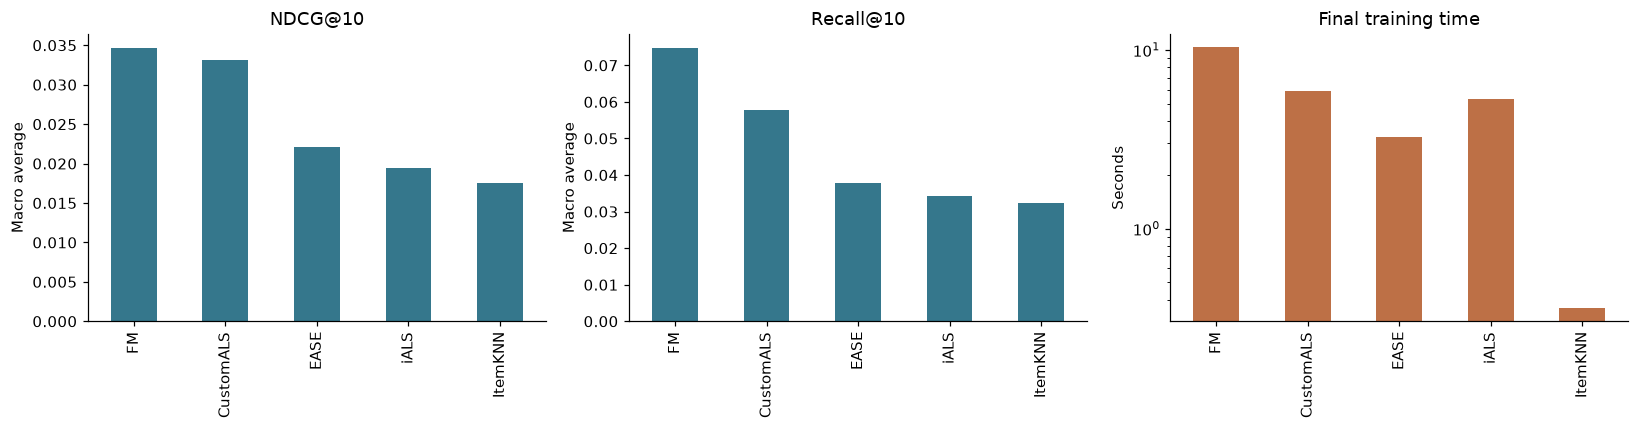

,comparison,delta NDCG@10,paired 95% interval
0,"Custom target − binary target, fixed settings",0.015344,"[0.003724, 0.027782]"
1,FM history/time metadata − IDs only,0.013757,"[0.002294, 0.024718]"
2,FM − selected CustomALS,0.001479,"[-0.01112, 0.013862]"
3,Recent popularity − FM,0.006563,"[-0.00575, 0.020426]"


,model,users,users with a hit
0,ItemKNN,677,29
1,iALS,677,30
2,EASE,677,33
3,FM,677,64
4,CustomALS,677,48
5,MostPopular,677,37
6,RecentPopular,677,55
7,CustomALS_controlled,677,48
8,FM_ID_only,677,33


In [8]:
scores = result['test'].set_index('model')
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, metric in zip(axes[:2], ['NDCG@10','Recall@10']):
    scores[metric].plot.bar(ax=ax, color='#35778c')
    ax.set(title=metric, ylabel='Macro average', xlabel='')
scores.fit_seconds.plot.bar(ax=axes[2], color='#bd7046')
axes[2].set(title='Final training time', ylabel='Seconds', yscale='log', xlabel='')
plt.tight_layout()
plt.show()

def paired_interval(first, second, repeats=2000):
    delta = np.asarray(first) - np.asarray(second)
    rng = np.random.default_rng(config.SEED)
    means = np.array([delta[rng.integers(0,len(delta),len(delta))].mean() for _ in range(repeats)])
    return float(delta.mean()), np.quantile(means, [.025,.975]).tolist()

per_user = result['per_user']
pairs = [
    ('Custom target − binary target, fixed settings', 'CustomALS_controlled', 'iALS'),
    ('FM history/time metadata − IDs only', 'FM', 'FM_ID_only'),
    ('FM − selected CustomALS', 'FM', 'CustomALS'),
    ('Recent popularity − FM', 'RecentPopular', 'FM'),
]
interval_rows = []
for label, first, second in pairs:
    delta, interval = paired_interval(per_user[first]['per_user_ndcg'], per_user[second]['per_user_ndcg'])
    interval_rows.append({'comparison': label, 'delta NDCG@10': delta, 'paired 95% interval': interval})
display(pd.DataFrame(interval_rows))

display(pd.DataFrame([
    {'model': name, 'users': len(values['per_user_ndcg']),
     'users with a hit': int(np.count_nonzero(values['per_user_ndcg']))}
    for name, values in per_user.items()
]))

## 6. Примеры рекомендаций

Первый пользователь из зафиксированной тестовой когорты; известные до T₂ товары исключены.
Название взято из снимка каталога для отображения и не используется при обучении.

In [9]:
examples = json.loads(Path('results/recommendation_examples.json').read_text())
chosen_user = examples['users'][0]
lookup = data['metadata'].set_index('item_idx')
example_rows = []
for model_name, recommendations in examples['recommendations'].items():
    for rank, item in enumerate(recommendations[0], 1):
        example_rows.append({'model':model_name, 'rank':rank, 'item':lookup.loc[item,'parent_asin'], 'title':lookup.loc[item,'title']})
print('Encoded user:', chosen_user)
display(pd.DataFrame(example_rows))

Encoded user: 11775


,model,rank,item,title
0,ItemKNN,1,B00NFXON1Q,Xbox One 500GB Console - Assassin's Creed Unity Bundle
1,ItemKNN,2,B09V5R5LSZ,Halo 5: Guardians 9 Gold REQ Packs – Xbox One [Digital Code]
2,ItemKNN,3,B00DTY9B0O,Titanfall Collector's Edition
3,ItemKNN,4,B01GW3H3U8,Xbox Wireless Controller – White
4,ItemKNN,5,B00CMQTUSS,Xbox One Wireless Controller (Without 3.5 millimeter headset jack)
5,ItemKNN,6,B00CMQTUY2,Xbox One Wireless Controller and Play & Charge Kit (Without 3.5 millimeter headset jack)
6,ItemKNN,7,B000N5Z2L4,Xbox Live Gold: 1 Month Membership [Digital Code]
7,ItemKNN,8,B00ZMBLKPG,Gears of War: Ultimate Edition – Xbox One
8,ItemKNN,9,B00EQNP8F4,Microsoft Xbox LIVE 12 Month Gold Membership (Physical Card)
9,ItemKNN,10,B00KSRV19E,Forza Horizon 2 for Xbox One


## 7. Выводы

Среди пяти конфигураций, выбранных по validation, максимальная точечная оценка у **FM**:
NDCG@10 **0,03468**, Recall@10 **0,07479**. Выбраны 16 факторов, learning rate 0,01,
регуляризация 0,001 и 6 эпох. Однако разность NDCG с настроенным CustomALS равна всего
0,00148; парный 95% интервал **[−0,01112; 0,01386]** включает ноль.
Убедительного единственного победителя по этому разбиению нет.

**Кастомный таргет помог при одинаковых настройках ALS.** Бинарный iALS дал NDCG 0,01947,
а CustomALS с теми же факторами, регуляризацией, confidence и seed - 0,03481.
Разность 0,01534, интервал **[0,00372; 0,02778]**. Это результат отдельного контролируемого
сравнения: он не заменяет конфигурацию CustomALS, выбранную на validation (NDCG 0,03320).
Сигнал сочетает знак и силу оценки с ослаблением старой истории.

**Временные и исторические признаки улучшили FM относительно ID-only** при тех же настройках:
0,03468 против 0,02092, разность 0,01376, интервал **[0,00229; 0,02472]**.
Это не проверка категорий или брендов - они использованы только для EDA и отображения.

**Простая давность объясняет часть результата.** Обычная популярность дала NDCG 0,02073,
а популярность с полураспадом 365 суток - **0,04124**, Recall 0,06715.
У последней выше точечная NDCG, у FM выше Recall. Для разности NDCG «популярность с давностью
минус FM» интервал **[−0,00575; 0,02043]** включает ноль.
По этому эксперименту нельзя уверенно приписать выигрыш именно персонализации.

В выбранной test-части 1 291 событие от 944 пользователей. Метрики считаются для 677 пользователей
хотя бы с одним релевантным событием; у них 1 005 событий, из которых 937 релевантны. На train приходится 97,98% выбранных событий; сохранено лишь 1,58% событий исходного
test-периода. Хотя бы одно попадание в top-10 есть у 64 пользователей для FM и у 55 для популярности
с давностью. Размеры и потери важны при чтении средних метрик.

**Ограничения:** один датасет, одно временное разбиение и seed, ретроспективный 5-core,
популярный каталог и активные пользователи. Наблюдаются отзывы вместо показов и покупок;
ненаблюдённые товары не являются гарантированно отрицательными. Широкие временные интервалы
усиливают смену каталога и интересов. Поиск параметров небольшой; равное число конфигураций
не означает одинаково полный поиск. Bootstrap описывает разброс пользователей этого разбиения,
интервалы не скорректированы на множественные сравнения. Offline-метрики не доказывают
причинного улучшения в онлайн-рекомендациях.